### Problem 7 : SISA - exact unlearning for neural networks, by design

⏱️ ~35 min · 🧭 Stage 3 (Exact unlearning for neural nets), rung 5 · 📄 `resources/papers/02-exact-unlearning/2019-bourtoule-sisa-machine-unlearning.pdf`

> 🔗 **Building on Problems 3 and 6 :** retraining is the only exact option for a network (Problem 6), and it costs a
> full training run every time. But in Problem 3 we made a forest forget Carol by retraining **10 of 50 trees** - not by
> being clever after the fact, but by **designing** the forest so each user lived in one shard.

SISA (Bourtoule et al., IEEE S&P 2021) brings exactly that idea to neural networks, and adds one more trick :

![SISA](assets/diagrams/05_sisa.png)

| Letter | Idea | Where you have seen it |
|---|---|---|
| **S**harded | split the data into K disjoint shards | the forest's shards (Problem 3) |
| **I**solated | one independent network per shard - shards never share information | each tree only saw its bag |
| **S**liced | inside a shard, feed the data in R slices and **save a checkpoint after each** | new |
| **A**ggregated | predict by averaging the K networks | the forest's vote |

To forget a row : find its shard and slice, reload that shard's checkpoint from *before* the slice, and retrain only
from there. Everything else is untouched - and the result is **exactly** what training without the row would give.

**TASK :** Build SISA, make it forget Carol exactly, prove it bit-for-bit, and measure the price you pay in accuracy for
cheap forgetting.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mul import lab, train, methods, audit, viz
viz.style()

L = lab.make_lab("carol")
full_retrain_cost = lab.FIT["epochs"] * len(L.Xr)            # example-gradients for one exact retrain (Problem 6)
monolithic = train.fit(lab.model_fn, L.X_train, L.y_train, seed=0, **lab.FIT)
print(f"one full retrain = {full_retrain_cost:,} example-gradients")

one full retrain = 73,020 example-gradients


> 🟢 **In plain words :** imagine writing a book in 5 separate notebooks, and photocopying each notebook after every
> chapter. If someone asks you to remove a sentence from chapter 3 of notebook 2, you take the photocopy from the end of
> chapter 2, and rewrite chapters 3 and 4 of *that notebook only*. The other four notebooks are never touched.

#### Step 1 : Train SISA (5 shards × 4 slices)

In [2]:
# Step 1: SISA with a random partition of the data
sisa = methods.SISA(lab.model_fn, n_shards=5, n_slices=4, epochs_per_slice=15, seed=0)
info_fit = sisa.fit(L.X_train, L.y_train)
print(f"SISA training cost : {info_fit['samples_processed']:,} example-gradients")
print(f"{'':28s}{'monolithic':>12s}{'SISA (K=5)':>12s}")
for name, X, y in [("accuracy on test", L.X_test, L.y_test), ("accuracy on Carol (D_f)", L.Xf, L.yf),
                   ("accuracy on unseen thick", L.X_like_forget, L.y_like_forget)]:
    print(f"{name:28s}{train.accuracy(monolithic, X, y):12.1%}{train.accuracy(sisa, X, y):12.1%}")

SISA training cost : 47,205 example-gradients
                              monolithic  SISA (K=5)
accuracy on test                   98.0%       98.1%
accuracy on Carol (D_f)           100.0%       82.5%
accuracy on unseen thick           77.5%       80.0%


#### Step 2 : Show the issue - where does Carol live ?

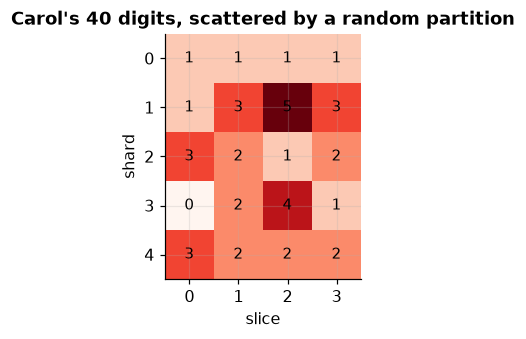

In [3]:
# Step 2: locate every one of Carol's rows
where = np.array([sisa.locate(i) for i in L.forget_idx])
grid = np.zeros((sisa.K, sisa.R), int)
for s, r in where:
    grid[s, r] += 1
fig, ax = plt.subplots(figsize=(5.5, 3.2))
im = ax.imshow(grid, cmap="Reds")
for s in range(sisa.K):
    for r in range(sisa.R):
        ax.text(r, s, grid[s, r], ha="center", va="center", fontsize=10)
ax.set_xlabel("slice"); ax.set_ylabel("shard"); ax.set_xticks(range(4)); ax.set_yticks(range(5))
ax.set_title("Carol's 40 digits, scattered by a random partition"); plt.tight_layout(); plt.show()

With a random partition, Carol's digits land in **every shard**, mostly in early slices. Just like the random-shard
forest in Problem 3, that means forgetting her touches everything.

#### Step 3 : Untrain - and compare two designs

In [4]:
# Step 3a: unlearn Carol from the random-partition SISA
_, info_random = sisa.unlearn(L.forget_idx)

# Step 3b: a USER-AWARE partition - Carol's data all in one shard, and in its LAST slice
#          (Bourtoule et al. also suggest putting data likely to be deleted into late slices)
rng = np.random.default_rng(0)
others = rng.permutation(L.retain_idx)
partition = [list(np.array_split(sh, 4)) for sh in np.array_split(others, 5)]
partition[0][3] = np.r_[partition[0][3], L.forget_idx]                   # shard 0, slice 4
sisa_user = methods.SISA(lab.model_fn, n_shards=5, n_slices=4, epochs_per_slice=15, seed=0)
sisa_user.fit(L.X_train, L.y_train, partition=partition)
before_user = (train.accuracy(sisa_user, L.Xf, L.yf), train.accuracy(sisa_user, L.X_test, L.y_test))
_, info_user = sisa_user.unlearn(L.forget_idx)

#### Step 4 : Show the result

design                        cost to forget Carol  % of retrain  shards touched  test acc
full retrain (Problem 6)                    73,020        100.0%               5     98.0%
SISA, random partition                      44,805         61.4%               5     98.0%
SISA, user-aware partition                   3,660          5.0%               1     97.0%

user-aware SISA on Carol's digits: before 67.5% -> after 65.0%


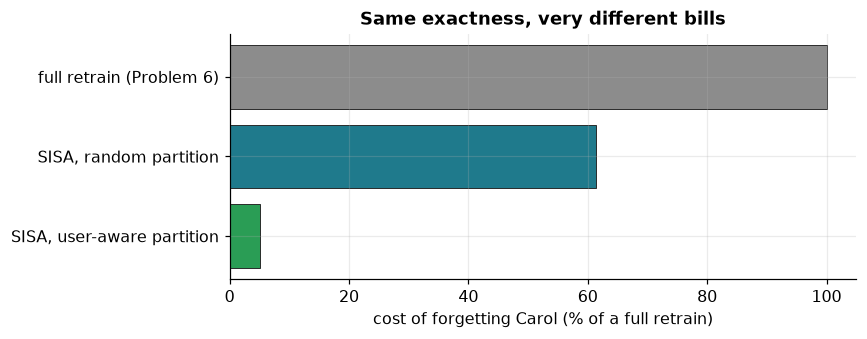

In [5]:
rows = [("full retrain (Problem 6)", full_retrain_cost, 5, train.accuracy(monolithic, L.X_test, L.y_test)),
        ("SISA, random partition", info_random["samples_processed"], info_random["shards_retrained"], train.accuracy(sisa, L.X_test, L.y_test)),
        ("SISA, user-aware partition", info_user["samples_processed"], info_user["shards_retrained"], train.accuracy(sisa_user, L.X_test, L.y_test))]
print(f"{'design':28s}{'cost to forget Carol':>22s}{'% of retrain':>14s}{'shards touched':>16s}{'test acc':>10s}")
for name, c, k, t in rows:
    print(f"{name:28s}{c:>22,}{c / full_retrain_cost:14.1%}{k:>16}{t:10.1%}")
print(f"\nuser-aware SISA on Carol's digits: before {before_user[0]:.1%} -> after {train.accuracy(sisa_user, L.Xf, L.yf):.1%}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh([r[0] for r in rows][::-1], [100 * r[1] / full_retrain_cost for r in rows][::-1],
        color=[viz.RETRAIN, "#1f7a8c", viz.ORIGINAL], edgecolor=viz.INK, lw=0.6)
ax.set_xlabel("cost of forgetting Carol (% of a full retrain)"); ax.set_title("Same exactness, very different bills")
plt.tight_layout(); plt.show()

The random partition saves some work (only the slices from Carol's earliest one onwards are redone), but the
**user-aware** design forgets Carol by retraining one slice of one shard - **5% of a full retrain** - and it is just as
exact.

One more thing worth noticing : even *before* unlearning, the user-aware SISA was far less sure about Carol's digits
than the monolithic network (it was not 100% on them). Her data lived in only one of five sub-models, and averaging
diluted her influence. Isolation is a mild **privacy defence** in its own right - the same intuition behind PATE-style
private ensembles.

#### Step 5 : Prove it - bit for bit

In [6]:
# Step 5: train a brand-new SISA from scratch with the same layout but WITHOUT Carol, and compare every weight
scratch = methods.SISA(lab.model_fn, n_shards=5, n_slices=4, epochs_per_slice=15, seed=0)
scratch.fit(L.X_train, L.y_train, partition=sisa_user.slices)            # Carol's rows are no longer in any slice
identical = all(train.weights_equal(a, b) for a, b in zip(sisa_user.shard_models, scratch.shard_models))
print(f"every weight of every shard identical to a from-scratch SISA without Carol: {identical}")
print(f"largest weight difference: {max(train.max_weight_diff(a, b) for a, b in zip(sisa_user.shard_models, scratch.shard_models)):.1e}")

every weight of every shard identical to a from-scratch SISA without Carol: True
largest weight difference: 0.0e+00


✅ **Bit-for-bit exact.** Not "close", not "indistinguishable to an attacker" - identical. That is the strongest
possible evidence, and it is what you can show a regulator.

#### The hidden trap : audit with the *same recipe*

Now a mistake that real audits make. Problem 5's per-example test (U-LiRA) needs reference models trained **with** and
**without** Carol. What happens if those references are trained with a *different recipe* from the model under audit ?

We audit three models whose truth we already know, against two sets of references :

In [7]:
# Reference models: monolithic networks, and SISA ensembles - each trained with and without Carol
def sisa_fit(X, y, seed):
    m = methods.SISA(lab.model_fn, 5, 4, 15, seed=seed); m.fit(X, y); return m

refs = {
    "monolithic refs": ([train.fit(lab.model_fn, L.X_train, L.y_train, seed=s, **lab.FIT) for s in range(1, 7)],
                        [train.fit(lab.model_fn, L.Xr, L.yr, seed=s, **lab.FIT) for s in range(11, 17)]),
    "SISA refs":       ([sisa_fit(L.X_train, L.y_train, s) for s in range(1, 7)],
                        [sisa_fit(L.Xr, L.yr, s) for s in range(11, 17)]),
}
truth = {
    "monolithic original  (REMEMBERS Carol)": monolithic,
    "monolithic retrain   (clean)": train.fit(lab.model_fn, L.Xr, L.yr, seed=50, **lab.FIT),
    "SISA unlearned       (clean, proven)": sisa_user,
}
print(f"{'model under audit':40s}{'monolithic refs':>17s}{'SISA refs':>12s}     (U-LiRA member-rate: high = 'still remembers')")
for name, m in truth.items():
    r = [audit.ulira(m, L.Xf, L.yf, ins, outs) for ins, outs in refs.values()]
    print(f"{name:40s}{r[0]:17.2f}{r[1]:12.2f}")

model under audit                         monolithic refs   SISA refs     (U-LiRA member-rate: high = 'still remembers')
monolithic original  (REMEMBERS Carol)               0.95        0.38
monolithic retrain   (clean)                         0.07        0.50
SISA unlearned       (clean, proven)                 0.00        0.07


**Stop and notice what just happened.** Read the monolithic models down the "SISA refs" column : the model that
genuinely **remembers** Carol scores *lower* than the clean retrain. With the wrong references, the audit is not just
noisy - it **ranks guilty below innocent**. With references that match each model's recipe (monolithic refs for the
monolithic models, SISA refs for SISA), every verdict is right.

The reason : an ensemble of five small networks has a different *confidence profile* from one big network, and
membership tests read confidence. Compare like with like.

> ⚠️ **Rule :** the gold standard and the shadow models must be produced by **the same training recipe** as the model
> under audit - same architecture, same sharding, same epochs. Problem 11 builds this into the audit.

#### The price of cheap forgetting : more shards, less accuracy

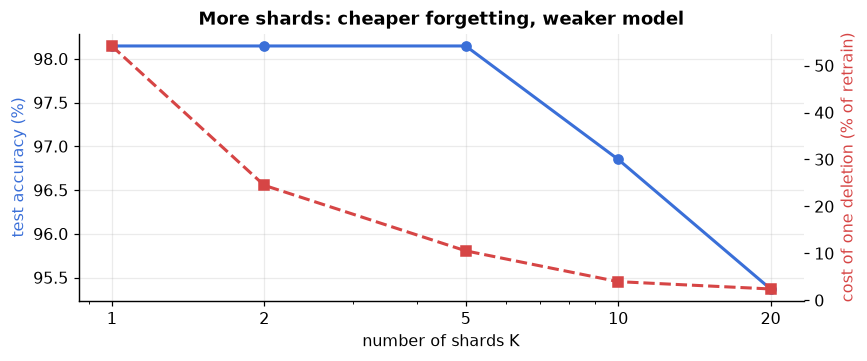

K= 1: test accuracy 98.1%   cost of one deletion  54.2% of a full retrain
K= 2: test accuracy 98.1%   cost of one deletion  24.5% of a full retrain
K= 5: test accuracy 98.1%   cost of one deletion  10.5% of a full retrain
K=10: test accuracy 96.9%   cost of one deletion   4.0% of a full retrain
K=20: test accuracy 95.4%   cost of one deletion   2.4% of a full retrain


In [8]:
# Trade-off: K shards -> test accuracy vs expected cost of forgetting ONE random user
Ks, accs, costs = [1, 2, 5, 10, 20], [], []
for K in Ks:
    m = methods.SISA(lab.model_fn, n_shards=K, n_slices=4, epochs_per_slice=15, seed=0)
    m.fit(L.X_train, L.y_train)
    accs.append(train.accuracy(m, L.X_test, L.y_test))
    c = []
    for i in np.random.default_rng(1).choice(L.retain_idx, 5, replace=False):
        mm = methods.SISA(lab.model_fn, n_shards=K, n_slices=4, epochs_per_slice=15, seed=0)
        mm.fit(L.X_train, L.y_train)
        c.append(mm.unlearn([i])[1]["samples_processed"])
    costs.append(np.mean(c) / full_retrain_cost)

fig, ax1 = plt.subplots(figsize=(8, 3.4))
ax1.plot(Ks, 100 * np.array(accs), "o-", color=viz.RETAIN, lw=2, label="test accuracy")
ax1.set_xscale("log"); ax1.set_xticks(Ks); ax1.set_xticklabels(Ks); ax1.set_xlabel("number of shards K"); ax1.set_ylabel("test accuracy (%)", color=viz.RETAIN)
ax2 = ax1.twinx(); ax2.plot(Ks, 100 * np.array(costs), "s--", color=viz.FORGET, lw=2, label="cost to forget 1 user")
ax2.set_ylabel("cost of one deletion (% of retrain)", color=viz.FORGET); ax2.grid(False)
ax1.set_title("More shards: cheaper forgetting, weaker model"); plt.tight_layout(); plt.show()
for K, a, c in zip(Ks, accs, costs):
    print(f"K={K:>2}: test accuracy {a:.1%}   cost of one deletion {c:6.1%} of a full retrain")

Up to K = 5 the ensemble loses nothing here; beyond that, each shard sees too little data and accuracy starts to fall,
while the cost of a deletion keeps shrinking. Note also that even K = 1 (no sharding, only slicing) halves the cost of
a deletion on average - checkpoints alone are worth having. With plenty of data per shard (or a strong pretrained
starting point) the accuracy drop stays small; with little data it hurts. Choosing
K is a business decision : expected deletion volume × retrain cost vs the accuracy you can afford to lose.

> 🔴 **For practitioners :** Bourtoule et al. report the accuracy cost grows for harder tasks and suggest **transfer
> learning** - start every shard from a shared pretrained model - to keep it small. That is exactly the pattern of
> modern fine-tuning: one frozen base model plus a small trainable part per shard or per tenant. Problem 15 builds it
> ("un-finetuning" by deleting a tenant's adapter). Also note SISA multiplies storage (K models × R checkpoints) and
> inference cost (K forward passes).

----
#### OUTCOME :

| Design | Exact ? | Cost to forget Carol | Test accuracy |
|---|---|---|---|
| Full retrain (Problem 6) | ✅ | 100% | 98% |
| SISA, random partition | ✅ bit-for-bit | ~60% of a retrain - she is in every shard | same (K = 5) |
| **SISA, user-aware partition** | ✅ bit-for-bit | **~5%** - one slice of one shard | about one point lower |

And one audit rule that will follow us to the end : **compare against references trained with the same recipe.**

#### Key Takeaways :

- SISA = the user-aware forest of Problem 3, rebuilt for neural networks, plus **slices + checkpoints**.
- It is **exact by construction** - we proved it bit-for-bit.
- The partition decides the bill : shard by the unit people delete (user, customer, document source), and put data
  likely to be deleted into **late slices**.
- More shards → cheaper deletion, lower accuracy. Pretrained starting points soften the drop.
- Audit an ensemble against an ensemble - **same recipe** or the verdict is meaningless.

#### TASK :
1. Put Carol in the **first** slice of shard 0 instead of the last. How does the cost of forgetting her change? Why?
2. Re-run the K trade-off with `epochs_per_slice=30`. Does more training per shard recover the lost accuracy?
3. Aggregate SISA by **majority vote** of the shards' predicted labels instead of averaging probabilities. Compare test
   accuracy and the membership-attack AUC from Problem 5.
4. Estimate SISA's *storage* cost for K=10, R=8 and this network (85k parameters, 4 bytes each). Then for a 100M-parameter
   model.

#### ❓ Open question → Problem 8
SISA must be decided **before** training. But most production models were trained monolithically, years ago, by someone
else - and a deletion request arrives today. **What can you do to a model that is already trained, without retraining
it?** Remember Problem 2's Newton step : it moved the weights using the deleted points' gradients. Problem 8 asks what
is left of that idea when there is no Hessian.